In [15]:
import yfinance as yf
import numpy as np
import statsmodels.api as sm
import statsmodels.tsa.stattools as ts
from statsmodels.tsa.stattools import coint
import pandas as pd
import matplotlib.pyplot as plt


ticker_1 = 'CEATLTD'            #higher price
ticker_2 = 'JKTYRE'             #lower price

start_date = '2026-01-01'
end_date = '2026-10-22'


#Creating a data frame to access and perform operations ,  MOST IMPORTANTLY DATES ALLIGN THE PRICES FOR THAT DAY
close = yf.download([ticker_1 + '.NS', ticker_2 + '.NS'], start_date, end_date)['Close']

y = close[ticker_1 + '.NS']
x = close[ticker_2 + '.NS']


constant = sm.add_constant(x)     #add constant/intercept so the line don't pass through origin
model = sm.OLS(y, constant).fit() #performing ols fit

#y = c + mx

#beta = model.params[ticker_2 + '.NS']

beta = model.params.iloc[1]
constt = model.params['const']  #generic name is const, can get it using params.iloc[0] as it's at first position


spread = model.resid


coint_t, p_value, crit_value = coint(y, x)  
print("strict p-value: ", p_value)


spread = y - (beta*x + constt)  #live
adf = ts.adfuller(spread)      #for predefined beta and constant
print("p-value live model: ", adf[1])


prev = spread.shift(1)   # y t-1
diff = spread - prev     # del y
prev = prev.dropna()    #NaN first row removal
diff = diff.dropna()

#to get psi or lamda slope of D-F equation

konst = sm.add_constant(prev)
modl = sm.OLS(diff, konst).fit()

lam = modl.params.iloc[1]    #value of slope 

half_life = -np.log(2)/lam

print("Half-Life: ", half_life)      #ideal: 5-30 days

[*********************100%***********************]  1 of 2 completed

strict p-value:  0.014928998487075055
p-value live model:  0.0033606955431846088
Half-Life:  6.613272706853856



/tmp/ipykernel_17383/1289948547.py:43: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = ts.adfuller(spread)      #for predefined beta and constant


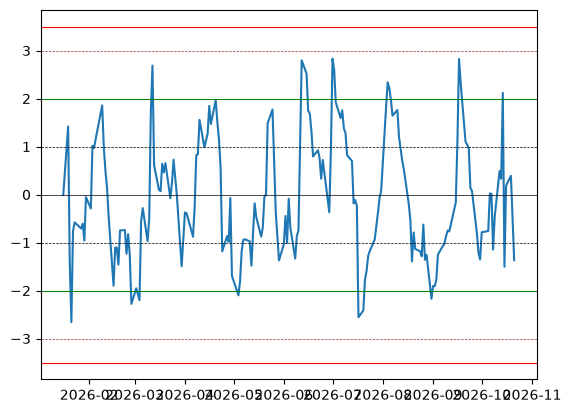

In [2]:
lookback = 12         #used for backtesting and setting most suitable value

roll_mean = spread.rolling(window = lookback).mean()
roll_std = spread.rolling(window = lookback).std()
z_score = (spread - roll_mean)/roll_std
z_score = z_score.dropna()

plt.plot(z_score.index, z_score)
plt.axhline(0, color='black', linewidth=0.5)
plt.axhline(1, color='black', linestyle='--', linewidth=0.5)
plt.axhline(-1, color='black', linestyle='--', linewidth=0.5)
plt.axhline(2, color='green', linewidth=0.7)
plt.axhline(-2, color='green', linewidth=0.7)
plt.axhline(3, color='brown', linestyle='--', linewidth=0.5)
plt.axhline(-3, color='brown', linestyle='--', linewidth=0.5)
plt.axhline(3.5, color='red', linewidth=0.8)
plt.axhline(-3.5, color='red', linewidth=0.8)